In [20]:
import pandas as pd
import numpy as np
import requests
import random
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# 1. Dataset generation and Model Training
np.random.seed(42)
n = 1000
feature_cols = ['Rainfall_mm', 'River_Discharge_m3s', 'Soil_Moisture', 'Humidity_%']

df = pd.DataFrame({
    'Rainfall_mm': np.random.uniform(0, 150, n),
    'River_Discharge_m3s': np.random.uniform(10, 2000, n),
    'Soil_Moisture': np.random.uniform(0.05, 0.50, n),
    'Humidity_%': np.random.uniform(20, 100, n)
})
df['Flood_Risk'] = np.where((df['Rainfall_mm'] > 60) & (df['River_Discharge_m3s'] > 900), 1, 0)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    df[feature_cols], df['Flood_Risk'], test_size=0.2, random_state=42, stratify=df['Flood_Risk']
)

# Optimal hyperparameters from Grid Search
model = RandomForestClassifier(max_depth=None, min_samples_split=2, n_estimators=200, random_state=42)
model.fit(X_train, y_train)

# Major Indian River Coordinates
hydro_locations = {
    "Ganga River (Varanasi, UP)": (25.3176, 83.0130),
    "Brahmaputra River (Guwahati, Assam)": (26.1833, 91.7458),
    "Kosi River (Supaul, Bihar)": (26.1260, 86.6050),
    "Yamuna River (Delhi)": (28.6139, 77.2485),
    "Godavari River (Rajahmundry, AP)": (17.0005, 81.7799),
    "Krishna River (Vijayawada, AP)": (16.5062, 80.6480),
    "Narmada River (Bharuch, Gujarat)": (21.7051, 72.9959),
    "Mahanadi River (Cuttack, Odisha)": (20.4625, 85.8830),
    "Alaknanda/Ganga (Rishikesh, Uttarakhand)": (30.0869, 78.2676)
}

def analyze_location(name, lat, lon):
    try:
        w_res = requests.get(
            f"https://api.open-meteo.com/v1/forecast?latitude={lat}&longitude={lon}"
            f"&current=precipitation,relative_humidity_2m,soil_moisture_0_to_1cm"
            f"&daily=precipitation_sum&forecast_days=7&timezone=auto", timeout=5
        ).json()

        f_res = requests.get(
            f"https://flood-api.open-meteo.com/v1/flood?latitude={lat}&longitude={lon}"
            f"&daily=river_discharge&forecast_days=7", timeout=5
        ).json()
    except Exception as e:
        print(f"❌ Network/API Error: {e}")
        return

    curr = w_res.get("current", {})
    rain = curr.get("precipitation", 0.0)
    hum = curr.get("relative_humidity_2m", 50.0)
    soil = curr.get("soil_moisture_0_to_1cm", 0.2)

    discharge_list = f_res.get("daily", {}).get("river_discharge", [50.0]*7)
    discharge_list = [d if d is not None else 50.0 for d in discharge_list]
    discharge = discharge_list[0]

    input_df = pd.DataFrame([[rain, discharge, soil, hum]], columns=feature_cols)
    pred = model.predict(input_df)[0]
    prob = model.predict_proba(input_df)[0][1] * 100
    status = f"⚠️ HIGH FLOOD RISK ({prob:.1f}% chance)" if pred == 1 else f"✅ SAFE ({prob:.1f}% chance)"

    print(f"📍 Location: {name} | Coordinates: ({lat:.4f}, {lon:.4f})")
    print(f"🌧️ Current Rainfall: {rain} mm | 🌊 River Discharge: {discharge:.1f} m³/s")
    print(f"🤖 Model Prediction: {status}\n")

    if "daily" in w_res and "daily" in f_res:
        dates = w_res["daily"]["time"]
        daily_rain = w_res["daily"]["precipitation_sum"]
        fig, ax1 = plt.subplots(figsize=(8, 3.5))
        ax1.bar(dates, daily_rain, color='skyblue', label='Rainfall (mm)', width=0.4)
        ax1.set_ylabel('Rainfall (mm)', color='blue')
        ax1.tick_params(axis='x', rotation=30)

        ax2 = ax1.twinx()
        ax2.plot(dates, discharge_list, color='darkblue', marker='o', linewidth=2, label='Discharge')
        ax2.set_ylabel('River Discharge (m³/s)', color='darkblue')
        plt.title(f"7-Day Hydrological Forecast - {name}")
        plt.tight_layout()
        plt.show()

def check_hydro(query="random"):
    if not query.strip():
        query = "random"
    if query.lower() == "random":
        chosen_name = random.choice(list(hydro_locations.keys()))
        lat, lon = hydro_locations[chosen_name]
        analyze_location(chosen_name, lat, lon)
    else:
        matches = [k for k in hydro_locations if query.lower() in k.lower()]
        if matches:
            chosen_name = matches[0]
            lat, lon = hydro_locations[chosen_name]
            analyze_location(chosen_name, lat, lon)
        else:
            try:
                geo = requests.get(f"https://geocoding-api.open-meteo.com/v1/search?name={query}&count=1", timeout=5).json()
                if "results" in geo:
                    lat, lon = geo["results"][0]["latitude"], geo["results"][0]["longitude"]
                    full_name = f"{geo['results'][0]['name']}, {geo['results'][0].get('admin1', '')} ({geo['results'][0].get('country', '')})"
                    analyze_location(full_name, lat, lon)
                else:
                    print(f"❌ '{query}' location not found.")
            except Exception as e:
                print(f"❌ Geocoding search failed: {e}")

📍 Location: Brahmaputra River (Guwahati, Assam) | Coordinates: (26.1833, 91.7458)
🌧️ Current Rainfall: 0.0 mm | 🌊 River Discharge: 0.2 m³/s
🤖 Model Prediction: ✅ SAFE (0.0% chance)



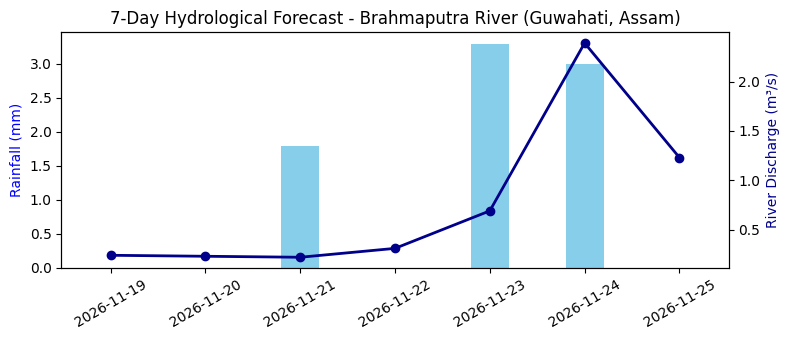

In [21]:
# @title 🔍 Real-time Flood Analysis Search Box
location_query = "Assam" # @param {type:"string"}
check_hydro(location_query)